In [1]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/simuteh-2330511067/notebook

Mounted at /content/drive
/content/drive/MyDrive/simuteh-2330511067/notebook


In [2]:
import sys
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil, kontras_bercak


In [3]:
import time

def konvolusi(img, k): # fungsi dari slide P4
    kh, kw = k.shape; ph, pw = kh // 2, kw // 2
    pad = np.pad(img.astype(float), ((ph, ph), (pw, pw)), mode="edge")
    out = np.zeros(img.shape)
    for y in range(img.shape[0]):
        for x in range(img.shape[1]):
            out[y, x] = np.sum(pad[y:y+kh, x:x+kw] * k)
    return np.clip(np.round(out), 0, 255).astype(np.uint8)

def konvolusi_sejati(img, k): # kernel dibalik 180 derajat dahulu
    return konvolusi(img, np.flip(k))

nama = "teh_041.png"
bersih = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nama}"),
                      cv2.COLOR_BGR2GRAY)
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)

for nm, k in {"rerata": np.ones((3, 3)) / 9,
              "asimetris": np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]], float)
              }.items():
    t0 = time.perf_counter(); a = konvolusi(bersih, k)
    t_manual = time.perf_counter() - t0
    t0 = time.perf_counter()
    b = cv2.filter2D(bersih, -1, k, borderType=cv2.BORDER_REPLICATE)
    t_cv = time.perf_counter() - t0
    beda = np.abs(a.astype(int) - b.astype(int)).max()
    c = konvolusi_sejati(bersih, k)
    beda2 = np.abs(c.astype(int) - b.astype(int)).max()
    print(f"{nm}: selisih manual vs filter2D={beda}, "
          f"sejati vs filter2D={beda2}, "
          f"waktu manual={t_manual:.3f} s, filter2D={t_cv:.5f} s")

rerata: selisih manual vs filter2D=0, sejati vs filter2D=0, waktu manual=1.386 s, filter2D=0.00773 s
asimetris: selisih manual vs filter2D=0, sejati vs filter2D=255, waktu manual=1.955 s, filter2D=0.00042 s


In [4]:
import pandas as pd
rng = np.random.default_rng(42)

def derau_gauss(img, sd):
    return np.clip(img + rng.normal(0, sd, img.shape), 0, 255).astype(np.uint8)

def derau_sp(img, p): # p = proporsi piksel rusak
    out = img.copy(); m = rng.random(img.shape)
    out[m < p / 2] = 0; out[m > 1 - p / 2] = 255
    return out

def ukur_waktu(f, x, ulang=20): # rerata beberapa kali, dalam ms
    t = []
    for _ in range(ulang):
        t0 = time.perf_counter(); f(x); t.append(time.perf_counter() - t0)
    return 1000 * np.mean(t)

derau = {"gauss_10": derau_gauss(bersih, 10), "gauss_20": derau_gauss(bersih, 20),
         "gauss_40": derau_gauss(bersih, 40), "sp_4%": derau_sp(bersih, 0.04),
         "sp_10%": derau_sp(bersih, 0.10)}

penapis = {"rerata_3": lambda x: cv2.blur(x, (3, 3)),
           "rerata_5": lambda x: cv2.blur(x, (5, 5)),
           "gauss_5": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
           "median_3": lambda x: cv2.medianBlur(x, 3),
           "median_5": lambda x: cv2.medianBlur(x, 5),
           "median_9": lambda x: cv2.medianBlur(x, 9)}

baris = []
for dn, d in derau.items():
    baris.append([dn, "tanpa", cv2.PSNR(bersih, d), 0.0, kontras_bercak(d, md, mb)])
    for pn, f in penapis.items():
        out = f(d)
        baris.append([dn, pn, cv2.PSNR(bersih, out), ukur_waktu(f, d), kontras_bercak(out, md, mb)])

tabel = pd.DataFrame(baris, columns=["derau", "penapis", "PSNR_dB", "waktu_ms", "KB"]).round(2)
print(tabel)
tabel.to_csv("../hasil/b4_tabel_penapis.csv", index=False)

       derau   penapis  PSNR_dB  waktu_ms    KB
0   gauss_10     tanpa    28.11      0.00  3.72
1   gauss_10  rerata_3    36.88      0.10  5.82
2   gauss_10  rerata_5    37.69      0.12  6.00
3   gauss_10   gauss_5    37.72      0.17  5.97
4   gauss_10  median_3    35.49      0.06  5.72
5   gauss_10  median_5    38.32      0.38  6.50
6   gauss_10  median_9    38.49      9.16  7.46
7   gauss_20     tanpa    22.11      0.00  2.12
8   gauss_20  rerata_3    31.43      0.09  4.64
9   gauss_20  rerata_5    34.52      0.11  5.42
10  gauss_20   gauss_5    32.58      0.20  4.95
11  gauss_20  median_3    29.74      0.08  4.18
12  gauss_20  median_5    33.43      0.59  5.32
13  gauss_20  median_9    35.41      9.37  6.10
14  gauss_40     tanpa    16.48      0.00  1.08
15  gauss_40  rerata_3    25.92      0.09  2.93
16  gauss_40  rerata_5    29.83      0.11  4.02
17  gauss_40   gauss_5    27.13      0.16  3.26
18  gauss_40  median_3    23.83      0.06  2.47
19  gauss_40  median_5    27.84      0.3

In [5]:
def selisih_rerata(kanal, mask_daun, mask_bercak):
    """dI = |rerata bercak - rerata daun sehat|, dalam satuan intensitas."""
    k = kanal.astype(float)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    return abs(k[mask_bercak > 0].mean() - k[sehat].mean())

label = pd.read_csv("../data/sintetis/label.csv")
baris = []
for nm in label[label.kelas == "ringan"].nama_file:
    g = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nm}"), cv2.COLOR_BGR2GRAY)
    md2 = cv2.imread(f"../data/sintetis/mask_daun/{nm}", 0)
    mb2 = cv2.imread(f"../data/sintetis/mask_bercak/{nm}", 0)
    for k in [1, 3, 5, 9, 15]: # k = 1 berarti tanpa penapis
        out = g if k == 1 else cv2.medianBlur(g, k)
        baris.append([nm, k, selisih_rerata(out, md2, mb2), kontras_bercak(out, md2, mb2)])

hasil_median = pd.DataFrame(baris, columns=["nama", "kernel", "dI", "KB"])
print(hasil_median.groupby("kernel")[["dI", "KB"]].mean().round(2))

           dI    KB
kernel             
1       24.56  3.87
3       24.72  3.95
5       23.37  3.79
9       15.93  2.96
15       6.46  1.65


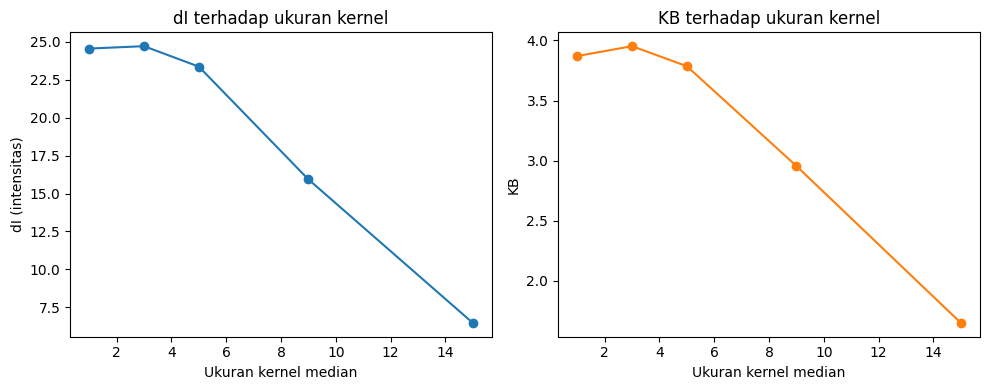

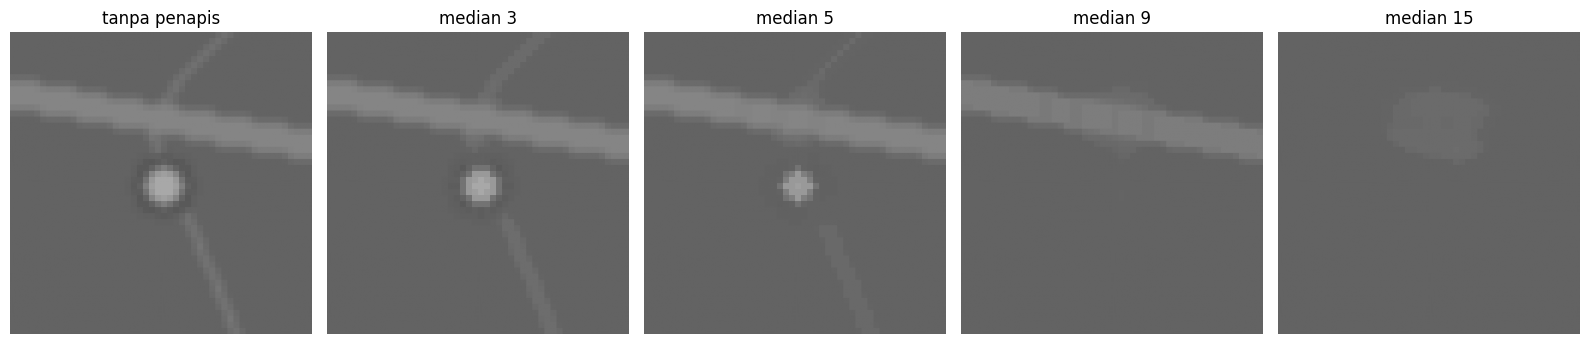

In [6]:
# 1. Grafik dI dan KB terhadap ukuran kernel
rata = hasil_median.groupby("kernel")[["dI", "KB"]].mean()
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(rata.index, rata["dI"], "o-")
ax[0].set_xlabel("Ukuran kernel median"); ax[0].set_ylabel("dI (intensitas)")
ax[0].set_title("dI terhadap ukuran kernel")
ax[1].plot(rata.index, rata["KB"], "o-", color="tab:orange")
ax[1].set_xlabel("Ukuran kernel median"); ax[1].set_ylabel("KB")
ax[1].set_title("KB terhadap ukuran kernel")
plt.tight_layout()
plt.savefig("../hasil/b4_di_vs_kernel.png")
plt.show()

# 2. Crop satu bercak, diperbesar, untuk tiap ukuran kernel
nm = "teh_021.png"
g = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nm}"), cv2.COLOR_BGR2GRAY)
mb2 = cv2.imread(f"../data/sintetis/mask_bercak/{nm}", 0)
n, lab, stat, cent = cv2.connectedComponentsWithStats(mb2)
i = 1 + np.argmax(stat[1:, cv2.CC_STAT_AREA])      # bercak terbesar
cx, cy = cent[i].astype(int)
y0, x0 = max(cy - 25, 0), max(cx - 25, 0)

potongan, judul = [], []
for k in [1, 3, 5, 9, 15]:
    out = g if k == 1 else cv2.medianBlur(g, k)
    c = out[y0:cy + 25, x0:cx + 25]
    potongan.append(cv2.resize(c, None, fx=6, fy=6, interpolation=cv2.INTER_NEAREST))
    judul.append("tanpa penapis" if k == 1 else f"median {k}")
tampil(potongan, judul, baris=1, ukuran=(16, 4))
plt.savefig("../hasil/b4_crop_bercak.png")

In [7]:
def unsharp(x, k=1.0):
    blur = cv2.GaussianBlur(x, (5, 5), 1.0)
    return cv2.addWeighted(x, 1 + k, blur, -k, 0)

noisy = derau["gauss_20"]
latar = md == 0 # area latar yang seharusnya rata

for nm, redam in {"Gaussian": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
                  "Median": lambda x: cv2.medianBlur(x, 5)}.items():
    A = redam(unsharp(noisy)) # tajamkan dulu, lalu redam
    B = unsharp(redam(noisy)) # redam dulu, lalu tajamkan
    print(f"{nm}: tajam->redam PSNR={cv2.PSNR(bersih, A):.2f} "
          f"sigma_latar={A[latar].std():.1f} | redam->tajam "
          f"PSNR={cv2.PSNR(bersih, B):.2f} sigma_latar={B[latar].std():.1f}")

Gaussian: tajam->redam PSNR=30.38 sigma_latar=7.9 | redam->tajam PSNR=30.20 sigma_latar=8.2
Median: tajam->redam PSNR=30.15 sigma_latar=8.1 | redam->tajam PSNR=31.12 sigma_latar=7.2


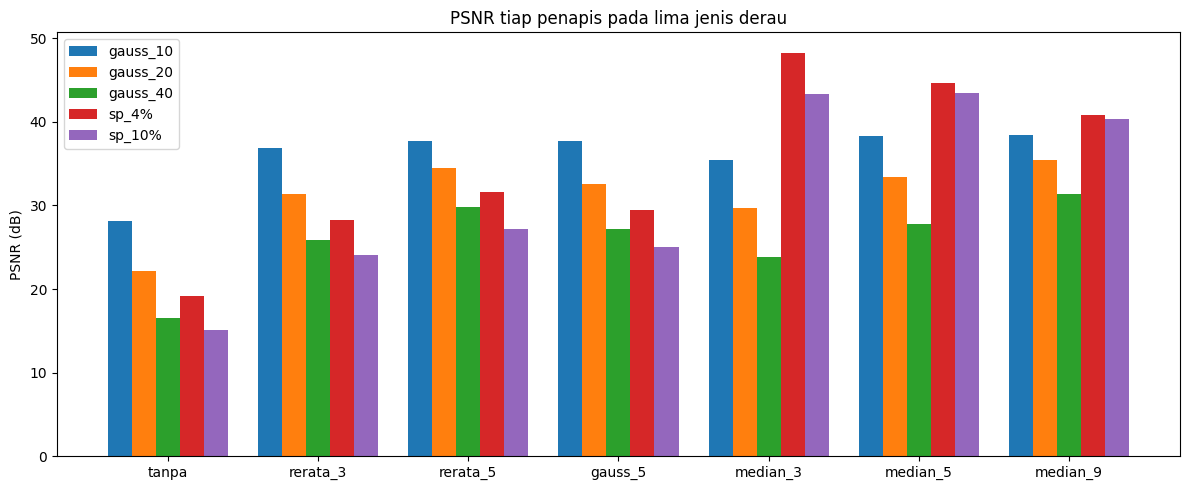

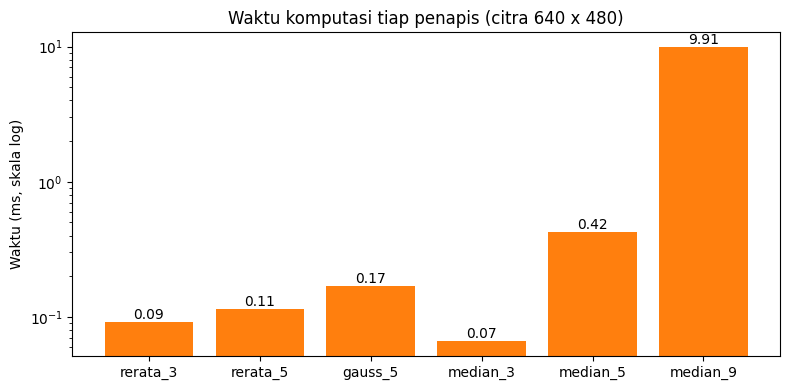

In [8]:
urut = ["tanpa", "rerata_3", "rerata_5", "gauss_5",
        "median_3", "median_5", "median_9"]
jenis = ["gauss_10", "gauss_20", "gauss_40", "sp_4%", "sp_10%"]

# 1. PSNR per penapis untuk tiap jenis derau
fig, ax = plt.subplots(figsize=(12, 5))
lebar = 0.16
x = np.arange(len(urut))
for i, dn in enumerate(jenis):
    sub = tabel[tabel.derau == dn].set_index("penapis").loc[urut]
    ax.bar(x + (i - 2) * lebar, sub["PSNR_dB"], lebar, label=dn)
ax.set_xticks(x); ax.set_xticklabels(urut)
ax.set_ylabel("PSNR (dB)"); ax.set_title("PSNR tiap penapis pada lima jenis derau")
ax.legend()
plt.tight_layout()
plt.savefig("../hasil/b4_grafik_psnr.png")
plt.show()

# 2. Waktu komputasi per penapis (rerata dari lima jenis derau, skala log)
waktu = (tabel[tabel.penapis != "tanpa"]
         .groupby("penapis")["waktu_ms"].mean().loc[urut[1:]])
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(waktu.index, waktu.values, color="tab:orange")
ax.set_yscale("log")
ax.set_ylabel("Waktu (ms, skala log)")
ax.set_title("Waktu komputasi tiap penapis (citra 640 x 480)")
for i, v in enumerate(waktu.values):
    ax.text(i, v, f"{v:.2f}", ha="center", va="bottom")
plt.tight_layout()
plt.savefig("../hasil/b4_grafik_waktu.png")
plt.show()

In [9]:
label = pd.read_csv("../data/sintetis/label.csv")
normal = label[label.kondisi_cahaya == "normal"].nama_file.tolist()
print(len(normal), normal)   # harus 12 citra: teh_001, 006, 011, ...

kandidat = {"gauss_5": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
            "median_3": lambda x: cv2.medianBlur(x, 3),
            "median_5": lambda x: cv2.medianBlur(x, 5)}

baris = []
for nm in normal:
    citra = cv2.cvtColor(baca(f"../data/sintetis/citra/{nm}"), cv2.COLOR_BGR2GRAY)
    bersih_i = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nm}"), cv2.COLOR_BGR2GRAY)
    r = [nm, cv2.PSNR(bersih_i, citra)]
    for pn, f in kandidat.items():
        r.append(cv2.PSNR(bersih_i, f(citra)))
    baris.append(r)

tabel46 = pd.DataFrame(baris, columns=["nama", "sebelum"] + list(kandidat)).round(2)
print(tabel46)
print(tabel46.drop(columns="nama").mean().round(2))
tabel46.to_csv("../hasil/b4_psnr_12_normal.csv", index=False)

12 ['teh_001.png', 'teh_006.png', 'teh_011.png', 'teh_016.png', 'teh_021.png', 'teh_026.png', 'teh_031.png', 'teh_036.png', 'teh_041.png', 'teh_046.png', 'teh_051.png', 'teh_056.png']
           nama  sebelum  gauss_5  median_3  median_5
0   teh_001.png    33.32    41.24     40.32     42.58
1   teh_006.png    32.08    40.59     39.27     41.89
2   teh_011.png    34.76    42.03     41.45     43.27
3   teh_016.png    32.55    41.16     39.64     41.99
4   teh_021.png    35.04    42.12     41.76     43.54
5   teh_026.png    33.39    41.48     40.40     42.52
6   teh_031.png    31.05    40.10     38.30     40.97
7   teh_036.png    33.12    41.60     40.23     42.63
8   teh_041.png    33.79    41.30     40.65     41.89
9   teh_046.png    32.12    40.36     39.15     41.18
10  teh_051.png    34.88    41.53     41.52     42.77
11  teh_056.png    28.99    38.41     36.32     39.08
sebelum     32.92
gauss_5     40.99
median_3    39.92
median_5    42.03
dtype: float64
